# TML-d24-varloop-research (IQ4_NL): Dual-T4 Pareto Benchmark

Sweep of `loop_num_passes = 1…5` for Thinking Machines Lab's variable-loop recurrent MoE checkpoint
(`TML-d24-varloop-research`, IQ4_NL GGUF, 17.6 GB) on the 35 HumanEval+ tasks with the longest canonical
solutions, served by `llama.cpp`'s `llama-server` on Kaggle's 2× Tesla T4.

**GitHub repo (scripts, results, write-up):** https://github.com/MFaiqKhan/tml-varloop-pareto-benchmark

This is a cleaned copy of the original Kaggle run: failed debugging cells were removed, and every remaining
cell keeps its **original saved output** from that run. Cells are in logical order, not execution order.

Pipeline:
1. Install a `llama-server` build that runs on T4 (CUDA 12.8) and make its CUDA runtime libraries visible
2. Download the GGUF checkpoint
3. Verify dual-T4 placement: naive layer split vs. explicit MoE expert override (`-ot`)
4. Full 35-task × 5-loop sweep
5. Summary table and Pareto plot

## 1. Install `llama-server` (CUDA 12.8 build)

The newest CUDA 13.5 build aborts on the T4 at the first graph compute with
`CUDA error: the provided PTX was compiled with an unsupported toolchain`. The CUDA 12.8 build plus its
`cudart` bundle works with Kaggle's driver.

In [ ]:
import os, glob, shutil, subprocess, tarfile, urllib.request, json

# 1. Remove the CUDA 13.5 binary folder to free ~650 MB (keeps /kaggle/working/models intact!)
shutil.rmtree("/kaggle/working/llama_bin", ignore_errors=True)
os.makedirs("/kaggle/working/llama_bin", exist_ok=True)
os.chdir("/kaggle/working/llama_bin")

# 2. Fetch the Ubuntu x64 CUDA 12 binary + cudart (100% compatible with Kaggle's CUDA 13.0 driver)
req = urllib.request.Request(
    "https://api.github.com/repos/ggml-org/llama.cpp/releases?per_page=5",
    headers={"User-Agent": "Mozilla/5.0"}
)
releases = json.loads(urllib.request.urlopen(req).read().decode())

bin_asset, cudart_asset = None, None
for rel in releases:
    assets = rel.get("assets", [])
    b = next((a for a in assets if "ubuntu-cuda-12" in a["name"] and "x64.tar.gz" in a["name"] and not a["name"].startswith("cudart-")), None)
    if b:
        bin_asset = b
        cudart_asset = next((a for a in assets if a["name"].startswith("cudart-") and "ubuntu-cuda-12" in a["name"] and "x64.tar.gz" in a["name"]), None)
        print(f"Found CUDA 12 release {rel['tag_name']}: {b['name']}")
        break

assert bin_asset is not None, "No Ubuntu CUDA 12 binary found!"

for item in [bin_asset, cudart_asset]:
    if item:
        print(f"Downloading {item['name']} ({item['size']/1e6:.1f} MB)...")
        urllib.request.urlretrieve(item["browser_download_url"], item["name"])
        with tarfile.open(item["name"], "r:gz") as tar:
            tar.extractall("/kaggle/working/llama_bin")
        os.remove(item["name"])  # Delete .tar.gz right after extracting to save disk space

server_bin = glob.glob("/kaggle/working/llama_bin/**/llama-server", recursive=True)[0]
server_dir = os.path.dirname(server_bin)
os.chmod(server_bin, 0o755)

env = os.environ.copy()
env["LD_LIBRARY_PATH"] = f"{server_dir}:{env.get('LD_LIBRARY_PATH', '')}"
out = subprocess.check_output([server_bin, "--version"], env=env, stderr=subprocess.STDOUT).decode()
print("Ready! Binary path:", server_bin)
print(out)

Found CUDA 12 release b12633: llama-b12633-bin-ubuntu-cuda-12.8-x64.tar.gz


Ready! Binary path: /kaggle/working/llama_bin/llama-b12633/llama-server
version: 1.0.0-dev (build 12633, commit 9c10c94e1)
built with GNU 13.3.0 for Linux x86_64



The `cudart` tarball extracts into a different folder than `llama-server`. Until `libcudart`/`libcublas`
sit next to the binary, `ggml-cuda` can't load and the server silently falls back to CPU (~5 tok/s).
Copying them over makes both T4s visible:

In [ ]:
import os, glob, shutil, subprocess

SERVER_DIR = "/kaggle/working/llama_bin/llama-b12633"
SERVER_BIN = f"{SERVER_DIR}/llama-server"

# Find all .so files extracted anywhere under /kaggle/working/llama_bin and copy them next to llama-server
for so_file in glob.glob("/kaggle/working/llama_bin/**/*.so*", recursive=True):
    dest = os.path.join(SERVER_DIR, os.path.basename(so_file))
    if not os.path.exists(dest):
        shutil.copy2(so_file, dest)
        print("Copied:", os.path.basename(so_file))

env = os.environ.copy()
env["LD_LIBRARY_PATH"] = f"{SERVER_DIR}:{env.get('LD_LIBRARY_PATH', '')}"

# Verify both Tesla T4 GPUs are detected by ggml-cuda!
out = subprocess.check_output([SERVER_BIN, "--list-devices"], env=env, cwd=SERVER_DIR, stderr=subprocess.STDOUT).decode()
print("\n=== DETECTED DEVICES ===")
print(out)

Copied: libcublasLt.so.12
Copied: libcudart.so.12
Copied: libcublas.so.12

=== DETECTED DEVICES ===
Available devices:
  CUDA0: Tesla T4 (14911 MiB, 14806 MiB free)
  CUDA1: Tesla T4 (14911 MiB, 14806 MiB free)



## 2. Download the checkpoint

Note: the 17.6 GB GGUF leaves only ~1.4 GB free on Kaggle's 21 GB `/kaggle/working` disk, so delete tarballs after extracting.

In [ ]:
!pip install -q huggingface_hub datasets openai pandas

import os
from huggingface_hub import hf_hub_download

os.makedirs("/kaggle/working/models", exist_ok=True)
path = hf_hub_download(
    repo_id="ggml-org/TML-d24-varloop-research-GGUF",
    filename="TML-d24-varloop-research-IQ4_NL.gguf",
    local_dir="/kaggle/working/models"
)
print("Downloaded successfully to:", path)

Downloaded successfully to: /kaggle/working/models/TML-d24-varloop-research-IQ4_NL.gguf


## 3. Dual-T4 placement check

**Baseline: partial offload with a plain layer split** (`-ngl 22`, `--tensor-split 0.45,0.55`, 3× loops).
GPU 1 is barely used and decode crawls:

In [ ]:
import os, subprocess, time, requests
from openai import OpenAI

MODEL_PATH = "/kaggle/working/models/TML-d24-varloop-research-IQ4_NL.gguf"
SERVER_BIN = "/kaggle/working/llama_bin/llama-b12633/llama-server"
SERVER_DIR = os.path.dirname(SERVER_BIN)
PORT = 8080

env = os.environ.copy()
env["LD_LIBRARY_PATH"] = f"{SERVER_DIR}:{env.get('LD_LIBRARY_PATH', '')}"

cmd = [
    SERVER_BIN, "-m", MODEL_PATH,
    "--override-kv", "inkling2_loop.loop.count=int:3",
    "--fit", "off",
    "-ngl", "22",
    "--split-mode", "layer",
    "--tensor-split", "0.45,0.55",
    "-c", "4096",
    "--jinja", "--temp", "1.0", "--port", str(PORT)
]

log_f = open("/kaggle/working/gpu_verify.log", "w")
proc = subprocess.Popen(cmd, stdout=log_f, stderr=subprocess.STDOUT, env=env, cwd=SERVER_DIR)

try:
    for _ in range(90):
        if proc.poll() is not None:
            with open("/kaggle/working/gpu_verify.log") as lf:
                raise RuntimeError(lf.read()[-2000:])
        try:
            if requests.get(f"http://127.0.0.1:{PORT}/health", timeout=2).status_code == 200:
                break
        except Exception:
            pass
        time.sleep(2)

    print("=== REAL NVIDIA-SMI VRAM CHECK ===")
    print(subprocess.check_output(["nvidia-smi", "--query-gpu=index,name,memory.used,utilization.gpu", "--format=csv"]).decode())

    client = OpenAI(base_url=f"http://127.0.0.1:{PORT}/v1", api_key="none")
    resp = client.chat.completions.create(
        model="tml-varloop",
        messages=[{"role": "user", "content": "Write a 5-line Python function to check if a number is prime."}],
        max_tokens=256
    )
    timings = resp.model_dump().get("timings") or {}
    print(f"GPU Decode Speed: {timings.get('predicted_per_second', 0):.1f} tokens/sec")
finally:
    proc.terminate()
    proc.wait(timeout=15)
    log_f.close()

=== REAL NVIDIA-SMI VRAM CHECK ===
index, name, memory.used [MiB], utilization.gpu [%]
0, Tesla T4, 8103 MiB, 0 %
1, Tesla T4, 995 MiB, 0 %

GPU Decode Speed: 2.5 tokens/sec


**Fix: offload everything and pin layers 12–23's fused MoE expert tensors to GPU 1**
(`-ngl 99 -ot "blk\.(1[2-9]|2[0-3])\.ffn_.*_exps=CUDA1"`). Memory is balanced across both cards,
and decode goes from 2.5 to 13.6 tok/s (5.4×) at the same 3× loop count:

In [ ]:
import os, subprocess, time, requests
from openai import OpenAI

MODEL_PATH = "/kaggle/working/models/TML-d24-varloop-research-IQ4_NL.gguf"
SERVER_BIN = "/kaggle/working/llama_bin/llama-b12633/llama-server"
SERVER_DIR = os.path.dirname(SERVER_BIN)
PORT = 8080

env = os.environ.copy()
env["LD_LIBRARY_PATH"] = f"{SERVER_DIR}:{env.get('LD_LIBRARY_PATH', '')}"

cmd = [
    SERVER_BIN, "-m", MODEL_PATH,
    "--override-kv", "inkling2_loop.loop.count=int:3",
    "--fit", "off",
    "-ngl", "99",
    "--split-mode", "layer",
    "--tensor-split", "1,1",
    "-ot", r"blk\.(1[2-9]|2[0-3])\.ffn_.*_exps=CUDA1",
    "-c", "4096",
    "--jinja", "--temp", "1.0", "--port", str(PORT)
]

log_f = open("/kaggle/working/gpu_verify.log", "w")
proc = subprocess.Popen(cmd, stdout=log_f, stderr=subprocess.STDOUT, env=env, cwd=SERVER_DIR)

try:
    for _ in range(90):
        if proc.poll() is not None:
            with open("/kaggle/working/gpu_verify.log") as lf:
                raise RuntimeError(lf.read()[-2000:])
        try:
            if requests.get(f"http://127.0.0.1:{PORT}/health", timeout=2).status_code == 200:
                break
        except Exception:
            pass
        time.sleep(2)

    print("=== REAL NVIDIA-SMI VRAM CHECK ===")
    print(subprocess.check_output(["nvidia-smi", "--query-gpu=index,name,memory.used,utilization.gpu", "--format=csv"]).decode())

    client = OpenAI(base_url=f"http://127.0.0.1:{PORT}/v1", api_key="none")
    resp = client.chat.completions.create(
        model="tml-varloop",
        messages=[{"role": "user", "content": "Write a 5-line Python function to check if a number is prime."}],
        max_tokens=256
    )
    timings = resp.model_dump().get("timings") or {}
    print(f"GPU Decode Speed: {timings.get('predicted_per_second', 0):.1f} tokens/sec")
finally:
    proc.terminate()
    proc.wait(timeout=15)
    log_f.close()

=== REAL NVIDIA-SMI VRAM CHECK ===
index, name, memory.used [MiB], utilization.gpu [%]
0, Tesla T4, 8695 MiB, 0 %
1, Tesla T4, 9697 MiB, 0 %

GPU Decode Speed: 13.6 tokens/sec


## 4. Full sweep: 35 tasks × loops 1–5

Settings: `temperature=1.0`, `reasoning_effort="medium"`, `max_tokens=2048`, one sample per task, 5 s test timeout.
175 generations; summed mean latency is ~4.1 h of generation time, plus server restarts.

In [ ]:
import os, sys, subprocess, time, re, tempfile, requests
import pandas as pd
from datasets import load_dataset
from openai import OpenAI

MODEL_PATH = "/kaggle/working/models/TML-d24-varloop-research-IQ4_NL.gguf"
SERVER_BIN = "/kaggle/working/llama_bin/llama-b12633/llama-server"
SERVER_DIR = os.path.dirname(SERVER_BIN)
PORT = 8080

server_env = os.environ.copy()
server_env["LD_LIBRARY_PATH"] = f"{SERVER_DIR}:{server_env.get('LD_LIBRARY_PATH', '')}"

# 1. Select the 35 hardest problems (longest canonical solutions) in HumanEval+
ds = load_dataset("evalplus/humanevalplus", split="test")
tasks = sorted(ds, key=lambda x: len(x["canonical_solution"]), reverse=True)[:35]

def get_total_vram_mb():
    out = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"]
    ).decode().strip().splitlines()
    return sum(int(x) for x in out)

def wait_for_server(proc, log_path, timeout=300):
    t0 = time.time()
    while time.time() - t0 < timeout:
        if proc.poll() is not None:
            with open(log_path) as lf:
                raise RuntimeError(f"llama-server exited early (code {proc.returncode}):\n{lf.read()[-2000:]}")
        try:
            if requests.get(f"http://127.0.0.1:{PORT}/health", timeout=2).status_code == 200:
                return
        except Exception:
            pass
        time.sleep(2)
    with open(log_path) as lf:
        raise RuntimeError(f"Server startup timed out after {timeout}s:\n{lf.read()[-2000:]}")

def check_solution_safe(raw_text, test_code, entry_point, timeout_sec=5):
    clean = re.sub(r"<think>.*?</think>", "", raw_text, flags=re.DOTALL).strip()
    m = re.search(r"```python\s*(.*?)```", clean, flags=re.DOTALL)
    code = m.group(1) if m else clean
    full_script = f"{code}\n\n{test_code}\n\ncheck({entry_point})\n"
    with tempfile.NamedTemporaryFile("w", suffix=".py", delete=False) as tf:
        tf.write(full_script)
        tmp_path = tf.name
    try:
        res = subprocess.run([sys.executable, tmp_path], timeout=timeout_sec, capture_output=True)
        return res.returncode == 0
    except Exception:
        return False
    finally:
        if os.path.exists(tmp_path):
            os.remove(tmp_path)

all_results = []

for loops in [1, 2, 3, 4, 5]:
    print(f"\n{'='*55}\nRunning Full 35-Task Sweep | loop_num_passes = {loops}\n{'='*55}")
    log_path = f"/kaggle/working/server_full_{loops}.log"
    
    cmd = [
        SERVER_BIN, "-m", MODEL_PATH,
        "--override-kv", f"inkling2_loop.loop.count=int:{loops}",
        "--fit", "off",
        "-ngl", "99",
        "--split-mode", "layer",
        "--tensor-split", "1,1",
        "-ot", r"blk\.(1[2-9]|2[0-3])\.ffn_.*_exps=CUDA1",
        "-c", "4096",
        "--jinja", "--temp", "1.0", "--port", str(PORT)
    ]
    log_f = open(log_path, "w")
    proc = subprocess.Popen(cmd, stdout=log_f, stderr=subprocess.STDOUT, env=server_env, cwd=SERVER_DIR)
    
    try:
        wait_for_server(proc, log_path)
        vram_mb = get_total_vram_mb()
        print(f"Server live | Total Dual-T4 VRAM: {vram_mb} MB ({vram_mb/1024:.2f} GB)")
        
        client = OpenAI(base_url=f"http://127.0.0.1:{PORT}/v1", api_key="none")
        
        for idx, row in enumerate(tasks):
            prompt = (
                "Complete this Python function. Output ONLY valid Python inside a ```python block.\n\n"
                + row["prompt"]
            )
            t0 = time.perf_counter()
            resp = client.chat.completions.create(
                model="tml-varloop",
                messages=[{"role": "user", "content": prompt}],
                max_tokens=2048,
                extra_body={"chat_template_kwargs": {"reasoning_effort": "medium"}}
            )
            dt = time.perf_counter() - t0
            
            out = resp.choices[0].message.content or ""
            comp_tokens = resp.usage.completion_tokens if resp.usage else 0
            
            raw_dump = resp.model_dump()
            timings = raw_dump.get("timings") or {}
            decode_tps = timings.get("predicted_per_second", comp_tokens / max(dt, 1e-5))
            prefill_tps = timings.get("prompt_per_second", 0.0)
            
            reasoning_text = raw_dump["choices"][0]["message"].get("reasoning_content") or ""
            if not reasoning_text:
                think_m = re.search(r"<think>(.*?)</think>", out, flags=re.DOTALL)
                reasoning_text = think_m.group(1) if think_m else ""
                
            passed = check_solution_safe(out, row["test"], row["entry_point"])
            
            all_results.append({
                "loops": loops,
                "task_id": row["task_id"],
                "passed": int(passed),
                "decode_tps": round(decode_tps, 2),
                "prefill_tps": round(prefill_tps, 2),
                "e2e_tps": round(comp_tokens / max(dt, 1e-5), 2),
                "latency_sec": round(dt, 2),
                "completion_tokens": comp_tokens,
                "think_chars": len(reasoning_text),
                "vram_gb": round(vram_mb / 1024, 2)
            })
            if (idx + 1) % 5 == 0 or idx == 0:
                print(f"[{loops}x] {idx+1:02d}/35 | {row['task_id']} | Pass={passed} | {decode_tps:.1f} tok/s | think={len(reasoning_text)}c")
    finally:
        proc.terminate()
        proc.wait(timeout=15)
        log_f.close()
        
    pd.DataFrame(all_results).to_csv("/kaggle/working/varloop_35_raw.csv", index=False)

print("\nDONE! Saved full results to /kaggle/working/varloop_35_raw.csv")


Running Full 35-Task Sweep | loop_num_passes = 1
Server live | Total Dual-T4 VRAM: 18386 MB (17.96 GB)
[1x] 01/35 | HumanEval/39 | Pass=False | 49.2 tok/s | think=6222c
[1x] 05/35 | HumanEval/93 | Pass=False | 49.3 tok/s | think=6339c
[1x] 10/35 | HumanEval/153 | Pass=True | 50.2 tok/s | think=1519c
[1x] 15/35 | HumanEval/6 | Pass=True | 49.6 tok/s | think=4171c
[1x] 20/35 | HumanEval/119 | Pass=False | 49.2 tok/s | think=6511c
[1x] 25/35 | HumanEval/59 | Pass=True | 50.6 tok/s | think=1400c
[1x] 30/35 | HumanEval/94 | Pass=True | 49.1 tok/s | think=5120c
[1x] 35/35 | HumanEval/69 | Pass=True | 50.3 tok/s | think=2115c

Running Full 35-Task Sweep | loop_num_passes = 2
Server live | Total Dual-T4 VRAM: 18916 MB (18.47 GB)
[2x] 01/35 | HumanEval/39 | Pass=False | 18.5 tok/s | think=2327c
[2x] 05/35 | HumanEval/93 | Pass=False | 18.1 tok/s | think=6347c
[2x] 10/35 | HumanEval/153 | Pass=True | 18.9 tok/s | think=2043c
[2x] 15/35 | HumanEval/6 | Pass=True | 19.5 tok/s | think=1607c
[2x] 2

## 5. Summary and Pareto plot

Caveat: N = 35 with a single sample at temperature 1.0, so one task = 2.86 pp. The 4× peak (77.1%) is
two more solved tasks than 2× / 3× (71.4%).

=== MARKDOWN TABLE FOR GITHUB / X ===
|   loops |   tasks |   pass_at_1 |   decode_tps |   avg_latency |   avg_tokens |   avg_think_chars |   vram_gb |
|--------:|--------:|------------:|-------------:|--------------:|-------------:|------------------:|----------:|
|       1 |      35 |        62.9 |         49.9 |          25.2 |         1190 |              3404 |     17.96 |
|       2 |      35 |        71.4 |         18.9 |          58.9 |         1079 |              3027 |     18.47 |
|       3 |      35 |        71.4 |         12.4 |          89.7 |         1071 |              2932 |     17.96 |
|       4 |      35 |        77.1 |          9.9 |         119.7 |         1137 |              3134 |     18.15 |
|       5 |      35 |        74.3 |          8.2 |         129   |         1025 |              2782 |     18.34 |


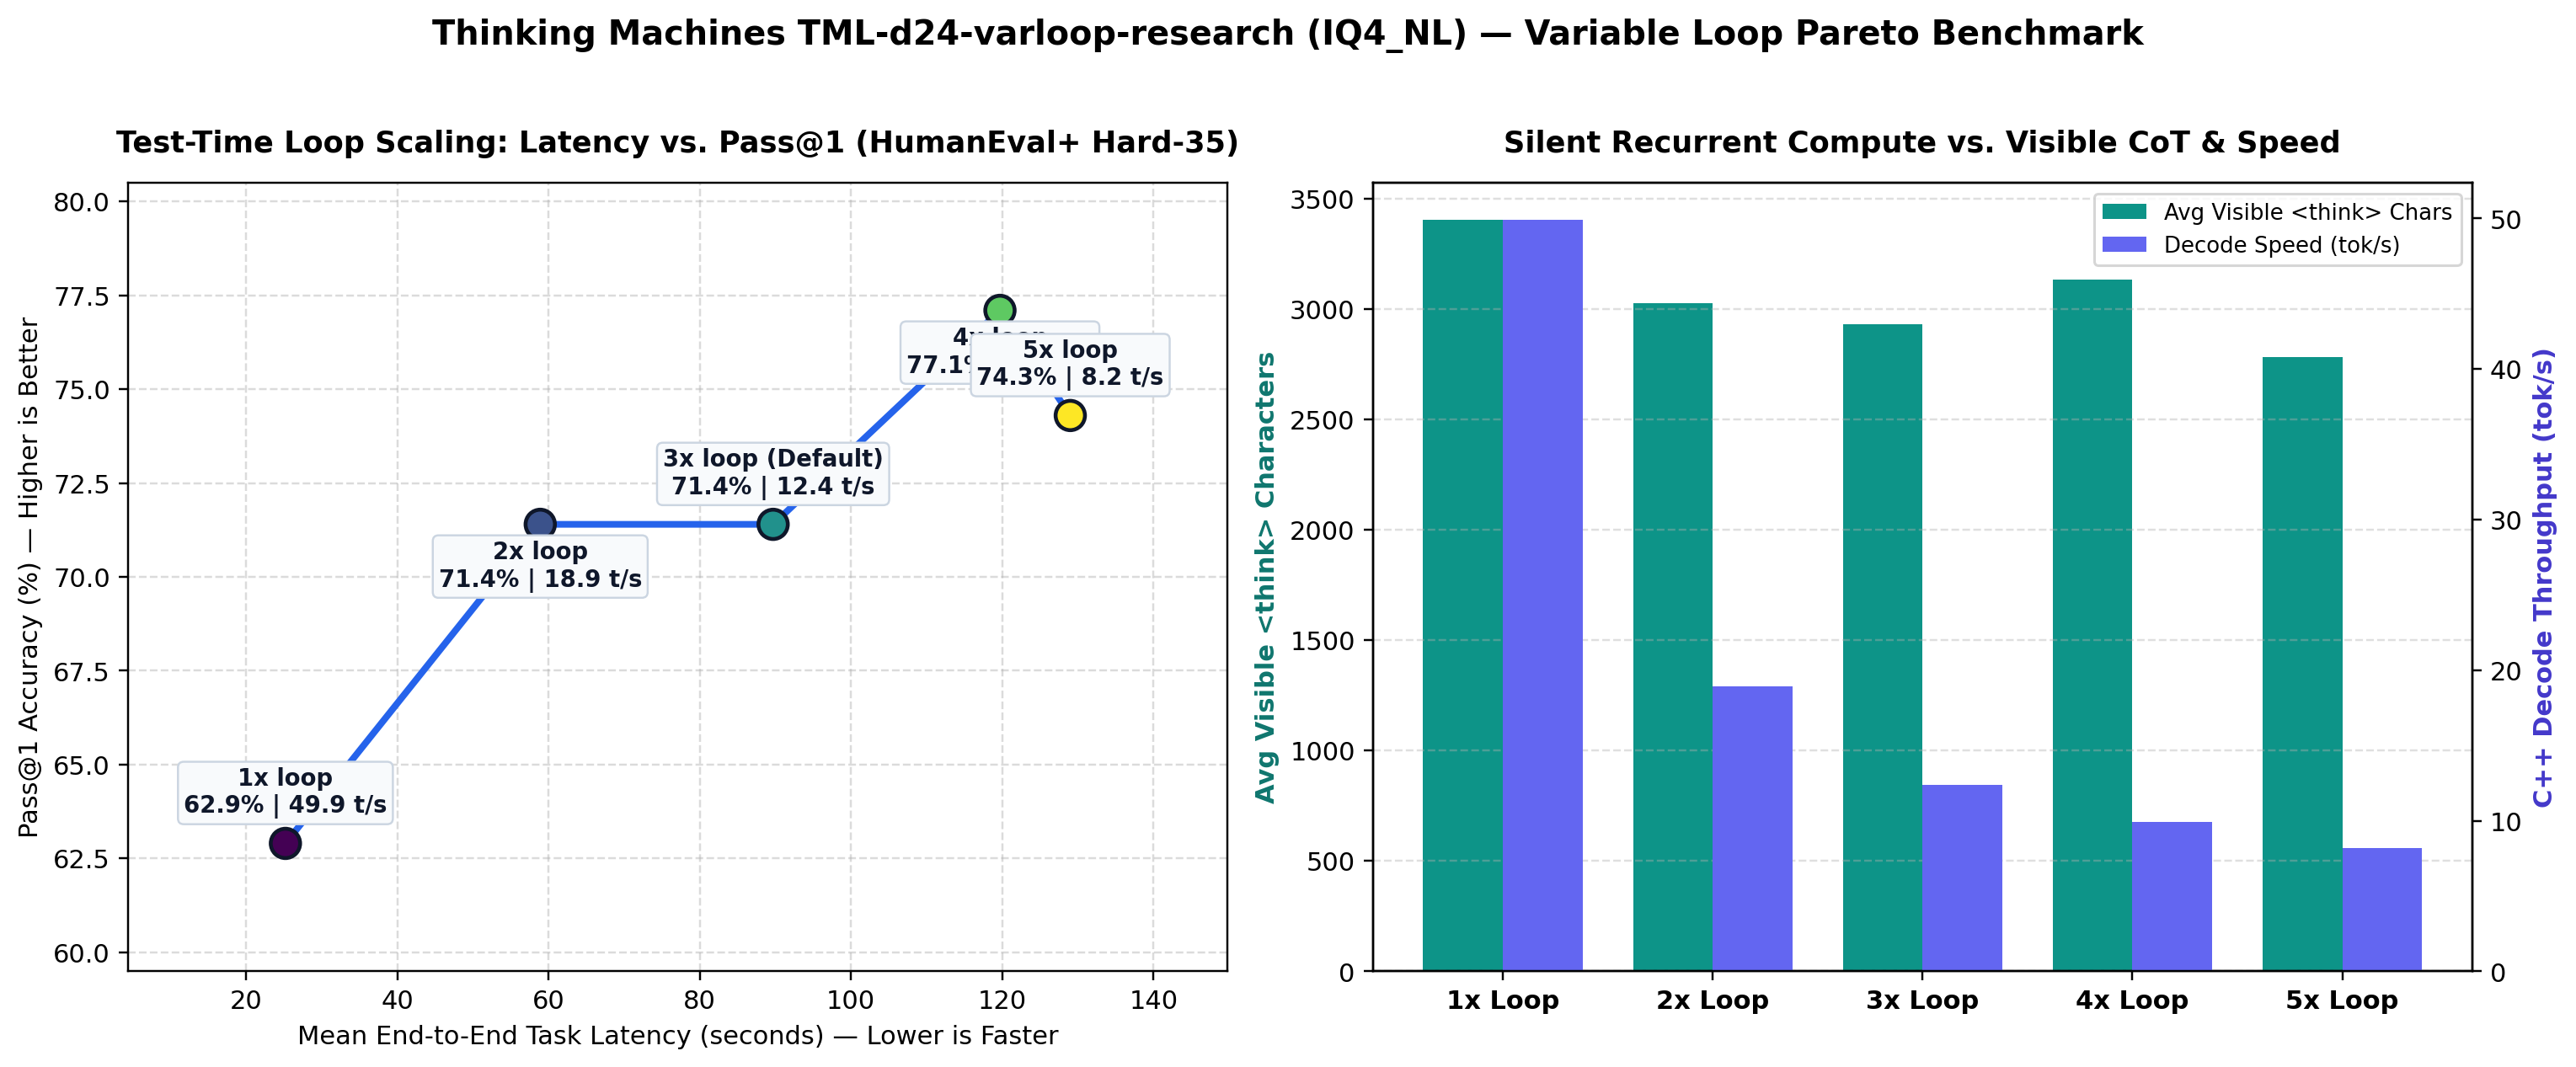

Saved high-res chart to /kaggle/working/inkling2_varloop_pareto_35.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/kaggle/working/varloop_35_raw.csv")

summary = df.groupby("loops").agg(
    tasks=("task_id", "count"),
    pass_at_1=("passed", lambda x: round(x.mean() * 100, 1)),
    decode_tps=("decode_tps", lambda x: round(x.mean(), 1)),
    avg_latency=("latency_sec", lambda x: round(x.mean(), 1)),
    avg_tokens=("completion_tokens", lambda x: round(x.mean(), 0)),
    avg_think_chars=("think_chars", lambda x: round(x.mean(), 0)),
    vram_gb=("vram_gb", "max")
).reset_index()

print("=== MARKDOWN TABLE FOR GITHUB / X ===")
print(summary.to_markdown(index=False))

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), dpi=220)
fig.patch.set_facecolor("#ffffff")

# --- PANEL 1: Pareto Frontier (Latency vs Pass@1 Accuracy) ---
ax1.plot(
    summary["avg_latency"], summary["pass_at_1"],
    color="#2563eb", linewidth=2.6, zorder=2
)
ax1.scatter(
    summary["avg_latency"], summary["pass_at_1"],
    s=130, c=summary["loops"], cmap="viridis", edgecolors="#0f172a", linewidth=1.5, zorder=3
)

for _, r in summary.iterrows():
    offset_y = 12 if r["loops"] % 2 == 1 else -24
    tag = " (Default)" if r["loops"] == 3 else ""
    ax1.annotate(
        f"{int(r['loops'])}x loop{tag}\n{r['pass_at_1']}% | {r['decode_tps']} t/s",
        (r["avg_latency"], r["pass_at_1"]),
        textcoords="offset points", xytext=(0, offset_y),
        ha="center", fontsize=9, fontweight="bold", color="#0f172a",
        bbox=dict(boxstyle="round,pad=0.25", fc="#f8fafc", ec="#cbd5e1", lw=0.8)
    )

ax1.set_title("Test-Time Loop Scaling: Latency vs. Pass@1 (HumanEval+ Hard-35)", fontsize=11.5, fontweight="bold", pad=12)
ax1.set_xlabel("Mean End-to-End Task Latency (seconds) — Lower is Faster", fontsize=10)
ax1.set_ylabel("Pass@1 Accuracy (%) — Higher is Better", fontsize=10)
ax1.margins(x=0.20, y=0.24)
ax1.grid(True, linestyle="--", alpha=0.45)

# --- PANEL 2: Silent Loops vs Visible CoT Length & Decode Throughput ---
x = np.arange(len(summary))
width = 0.38

ax2.bar(x - width/2, summary["avg_think_chars"], width, label="Avg Visible <think> Chars", color="#0d9488")
ax2_twin = ax2.twinx()
ax2_twin.bar(x + width/2, summary["decode_tps"], width, label="Decode Speed (tok/s)", color="#6366f1")

ax2.set_title("Silent Recurrent Compute vs. Visible CoT & Speed", fontsize=11.5, fontweight="bold", pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels([f"{int(l)}x Loop" for l in summary["loops"]], fontweight="bold")
ax2.set_ylabel("Avg Visible <think> Characters", color="#0f766e", fontsize=10, fontweight="bold")
ax2_twin.set_ylabel("C++ Decode Throughput (tok/s)", color="#4338ca", fontsize=10, fontweight="bold")
ax2.grid(True, axis="y", linestyle="--", alpha=0.4)

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc="upper right", frameon=True, fontsize=8.5)

fig.suptitle(
    "Thinking Machines TML-d24-varloop-research (IQ4_NL) — Variable Loop Pareto Benchmark",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig("/kaggle/working/inkling2_varloop_pareto_35.png", bbox_inches="tight")
plt.show()
print("Saved high-res chart to /kaggle/working/inkling2_varloop_pareto_35.png")